In [1]:
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
IMG_SIZE = (64, 64)
CLASS_NAMES = ["cat", "dog"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
MAX_PER_CLASS = 1000


In [3]:
def extract_features(path):
    img = Image.open(path).convert("L").resize(IMG_SIZE)
    return hog(np.asarray(img), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))

def label_from_parts(parts):
    for part in parts:
        p = part.lower()
        if p.startswith("cat"): return 0
        if p.startswith("dog"): return 1
    return None

In [4]:
data_dir = Path("data")
buckets = {0: [], 1: []}
for path in data_dir.rglob("*"):
    if path.suffix.lower() in IMAGE_EXTS:
        label = label_from_parts(path.relative_to(data_dir).parts[:-1])
        if label is not None:
            buckets[label].append(path)
print(f"Found {len(buckets[0])} cat and {len(buckets[1])} dog images")

Found 0 cat and 0 dog images


In [5]:
rng = random.Random(42)
paths, labels = [], []
for label, files_ in buckets.items():
    rng.shuffle(files_)
    for f in files_[:MAX_PER_CLASS]:
        paths.append(f); labels.append(label)

In [13]:
# Automatically re-build the dataset paths and buckets from the newly downloaded files
data_dir = Path("data")
buckets = {0: [], 1: []}
for path in data_dir.rglob("*"):
    if path.suffix.lower() in IMAGE_EXTS:
        label = label_from_parts(path.relative_to(data_dir).parts[:-1])
        if label is not None:
            buckets[label].append(path)

rng = random.Random(42)
paths, labels = [], []
for label, files_ in buckets.items():
    rng.shuffle(files_)
    for f in files_[:MAX_PER_CLASS]:
        paths.append(f)
        labels.append(label)

# Perform feature extraction and train_test_split
X = np.array([extract_features(p) for p in paths])
y = np.array(labels)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

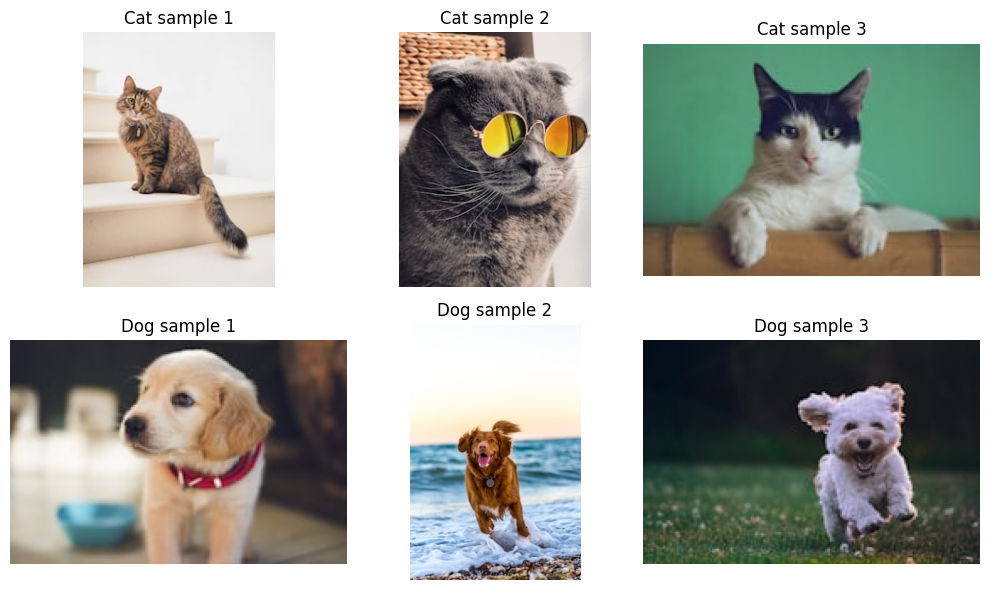

In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import random
from pathlib import Path

# Retrieve image paths
data_dir = Path("data")
cat_paths = list((data_dir / "cats").glob("*"))
dog_paths = list((data_dir / "dogs").glob("*"))

# Select 3 random samples from each class if available
sample_cats = random.sample(cat_paths, min(3, len(cat_paths)))
sample_dogs = random.sample(dog_paths, min(3, len(dog_paths)))

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

# Plot cats
for idx, path in enumerate(sample_cats):
    img = Image.open(path)
    axes[0, idx].imshow(img)
    axes[0, idx].set_title(f"Cat sample {idx+1}")
    axes[0, idx].axis("off")

# Plot dogs
for idx, path in enumerate(sample_dogs):
    img = Image.open(path)
    axes[1, idx].imshow(img)
    axes[1, idx].set_title(f"Dog sample {idx+1}")
    axes[1, idx].axis("off")

plt.tight_layout()
plt.show()

=== Performance Metrics on Expanded Dataset ===
              precision    recall  f1-score   support

         cat       0.00      0.00      0.00         3
         dog       0.50      0.75      0.60         4

    accuracy                           0.43         7
   macro avg       0.25      0.38      0.30         7
weighted avg       0.29      0.43      0.34         7



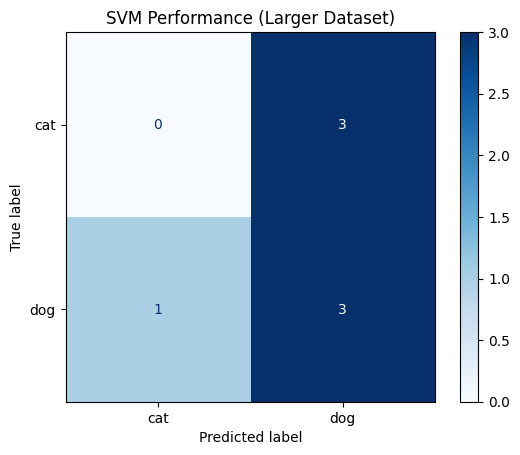

In [17]:
import urllib.request
from pathlib import Path
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create folders for the larger dataset
large_data_dir = Path("large_data")
large_data_dir.mkdir(exist_ok=True)
(large_data_dir / "cats").mkdir(exist_ok=True)
(large_data_dir / "dogs").mkdir(exist_ok=True)

# Expanded list of Unsplash source image URLs (approx. 20 cats and 20 dogs)
urls_large = {
    "cats": [
        "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1519052537078-e6302a4968d4?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1495360010541-f48722b34f7d?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1533738363-b7f9aef128ce?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1573865526739-10659fec78a5?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1518791841217-8f162f1e1131?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1561948955-570b270e7c36?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1472491235688-bdc81a63246e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1526336028061-b3b8f6af7f13?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1533743983669-94fa5c4338ec?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1513360309081-36f20cb802d0?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1501196354995-cbb51c65aaea?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1543466835-00a7907e9de1?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1592194996308-7b43878e84a6?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1557008075-7f2c5efa4cfd?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1574158622643-69d34d72650a?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1593487568522-746db8894991?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1586042091284-bd35c8c1d917?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1536590158209-e9d615d525e4?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1511275539165-cc46b1ee8960?auto=format&fit=crop&q=80&w=200"
    ],
    "dogs": [
        "https://images.unsplash.com/photo-1543466835-00a7907e9de1?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1534361960057-19889db9621e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1517841905240-472988babdf9?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1548199973-03cce0bbc87b?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1507146426996-ef05306b995a?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1530281700549-e82e7bf110d6?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1444212477490-ca407925329e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1552053831-71594a27632d?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1518020382113-a7e8fc38eac9?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1560807707-8cc77767d783?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1587300003388-59208cc962cb?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1598133185509-24aa411db34d?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1503256207526-0d5d80fa2f47?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1513245543132-31f507417b26?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1558788353-f76d92427f16?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1537151608828-ea2b117b6297?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1583337130417-3346a1be7dee?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1596492784531-6e6eb5ea9993?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1510771433102-60914a428873?auto=format&fit=crop&q=80&w=200"
    ]
}

headers = {'User-Agent': 'Mozilla/5.0'}

# Download the larger set of images
for label, url_list in urls_large.items():
    for i, url in enumerate(url_list):
        try:
            req = urllib.request.Request(url, headers=headers)
            filepath = large_data_dir / label / f"{label}_{i}.jpg"
            if not filepath.exists():
                with urllib.request.urlopen(req) as response, open(filepath, 'wb') as out_file:
                    out_file.write(response.read())
        except Exception as e:
            pass

# Re-extract features with the newly expanded set
paths_large, labels_large = [], []
for label_val, name in [(0, "cats"), (1, "dogs")]:
    files = list((large_data_dir / name).glob("*.jpg"))
    for f in files:
        paths_large.append(f)
        labels_large.append(label_val)

X_large = np.array([extract_features(p) for p in paths_large])
y_large = np.array(labels_large)

# Train-test split (80-20)
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_large, y_large, test_size=0.2, stratify=y_large, random_state=42
)

# Train and evaluate model
model_large = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0))
model_large.fit(X_train_l, y_train_l)
y_pred_l = model_large.predict(X_test_l)

# Print detailed precision/recall classification report
print("=== Performance Metrics on Expanded Dataset ===")
print(classification_report(y_test_l, y_pred_l, target_names=CLASS_NAMES))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test_l, y_pred_l, display_labels=CLASS_NAMES, cmap="Blues")
plt.title("SVM Performance (Larger Dataset)")
plt.show()

In [7]:
import os
from pathlib import Path

print("Current Working Directory:", os.getcwd())
print("Contents of Current Directory:")
for item in Path(".").iterdir():
    suffix = "/" if item.is_dir() else ""
    print(f" - {item.name}{suffix}")

Current Working Directory: /content
Contents of Current Directory:
 - .config/
 - sample_data/


In [11]:
import urllib.request
from pathlib import Path

# Create the data directory
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
(data_dir / "cats").mkdir(exist_ok=True)
(data_dir / "dogs").mkdir(exist_ok=True)

# More reliable sample URLs (Source: Unsplash source IDs)
urls = {
    "cats": [
        "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1519052537078-e6302a4968d4?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1495360010541-f48722b34f7d?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1533738363-b7f9aef128ce?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1573865526739-10659fec78a5?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1543466835-00a7907e9de1?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1518791841217-8f162f1e1131?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1561948955-570b270e7c36?auto=format&fit=crop&q=80&w=200"
    ],
    "dogs": [
        "https://images.unsplash.com/photo-1543466835-00a7907e9de1?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1534361960057-19889db9621e?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1517841905240-472988babdf9?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1548199973-03cce0bbc87b?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1507146426996-ef05306b995a?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1530281700549-e82e7bf110d6?auto=format&fit=crop&q=80&w=200",
        "https://images.unsplash.com/photo-1444212477490-ca407925329e?auto=format&fit=crop&q=80&w=200"
    ]
}

headers = {'User-Agent': 'Mozilla/5.0'}

# Download images into their respective folders
for label, url_list in urls.items():
    for i, url in enumerate(url_list):
        try:
            req = urllib.request.Request(url, headers=headers)
            filepath = data_dir / label / f"{label}_{i}.jpg"
            with urllib.request.urlopen(req) as response, open(filepath, 'wb') as out_file:
                out_file.write(response.read())
            print(f"Downloaded {filepath}")
        except Exception as e:
            print(f"Failed to download {url}: {e}")

Downloaded data/cats/cats_0.jpg
Downloaded data/cats/cats_1.jpg
Downloaded data/cats/cats_2.jpg
Downloaded data/cats/cats_3.jpg
Downloaded data/cats/cats_4.jpg
Downloaded data/cats/cats_5.jpg
Downloaded data/cats/cats_6.jpg
Downloaded data/cats/cats_7.jpg
Downloaded data/dogs/dogs_0.jpg
Downloaded data/dogs/dogs_1.jpg
Downloaded data/dogs/dogs_2.jpg
Downloaded data/dogs/dogs_3.jpg
Downloaded data/dogs/dogs_4.jpg
Downloaded data/dogs/dogs_5.jpg
Downloaded data/dogs/dogs_6.jpg
Downloaded data/dogs/dogs_7.jpg


Accuracy: 0.7500
              precision    recall  f1-score   support

         cat       1.00      0.50      0.67         2
         dog       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



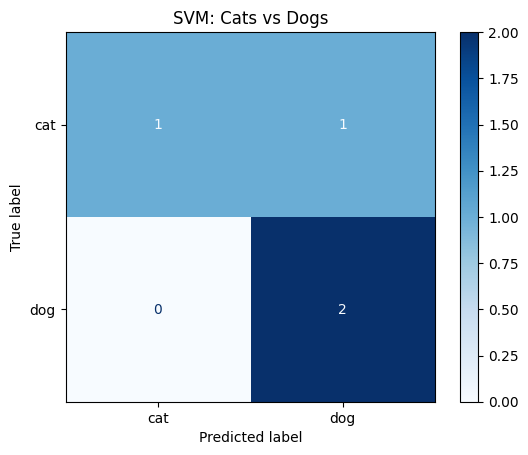

In [14]:
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues")
plt.title("SVM: Cats vs Dogs")
plt.show()